# Energy Forecasting — RNN, LSTM, GRU & CNN–RNN
## Google Colab T4 GPU • Autosave • Resume after Disconnection

**This is the consolidated assignment notebook, rebuilt from the three provided energy-forecasting notebooks.** It retains all **five sequence-modeling typologies** for each model family and executes **25 experiments**: 15 stacked RNN/LSTM/GRU, 5 original RNN baselines, and 5 CNN–RNN variants. Every experiment trains for **100 epochs** with the same real hourly energy dataset and chronological data partitions.

**What changed for Colab:**

- Reads `My Drive/Bioinformatics/Dataset/energy_dataset.csv` directly after mounting Google Drive. **No synthetic-data fallback.**
- Checks for NVIDIA GPU and displays the GPU type before training.
- Saves training-recovery data to Drive **after every epoch**. After a disconnect, rerun **Runtime → Run all** to resume; don't delete the results folder.
- Saves each completed model, metrics, and training history to Drive. Already completed experiments are skipped on subsequent runs.
- Prints progress every 10 epochs, gives a rough running estimate, and refreshes the combined metrics CSV after each completed model.
- At 25/25 completed experiments, produces summary tables, figures, a findings report, and a ZIP of submission outputs.

**Accuracy note:** All numerical comparisons are populated **only after actual training**. Cross-typology rankings are descriptive because the forecast horizon/output structure changes with the typology. For causal comparison of CNN vs RNN, compare the same typology and test set.

**Source typologies:** One-to-One; Many-to-One; One-to-Many; Many-to-Many (Synced); Many-to-Many (Encoder–Decoder/Seq2Seq).

### How to run (one notebook only)
1. Google Colab → **Runtime → Change runtime type → T4 GPU → Save**.
2. Open this notebook; choose **Runtime → Run all** and authorize Google Drive mounting.
3. Confirm **NVIDIA T4** is detected and **REAL** `energy_dataset.csv` is loaded.
4. You can leave the training running. If Colab disconnects, open the same notebook and click **Run all** again. It will reuse completed experiments and recovery checkpoints.
5. Find results in **My Drive → Bioinformatics → EnergyForecasting_Results → run_…**.

**Notes:** A T4 can train these architectures sequentially, but free Colab sessions can still end before all 25 models finish. The resume system is designed for that. Google Drive checkpointing adds some I/O time in exchange for not losing entire models. **Do not run the same experiment in two Colab sessions simultaneously.**

## 1. Imports, TensorFlow and T4 GPU check

In [ ]:
import os, gc, json, hashlib, time, math, shutil, zipfile, traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
print('TensorFlow:', tf.__version__)
print('Keras:', tf.keras.__version__ if hasattr(tf.keras, '__version__') else 'tf.keras')

GPUS = tf.config.list_physical_devices('GPU')
print('TensorFlow GPUs:', GPUS)
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print('Memory-growth setting:', exc)
try:
    import subprocess
    result = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                            capture_output=True, text=True, timeout=15)
    if result.returncode == 0:
        print('NVIDIA hardware:', result.stdout.strip())
except (FileNotFoundError, subprocess.TimeoutExpired):
    pass

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.keras.utils.set_random_seed(RANDOM_SEED)

TensorFlow: 2.21.0
Keras: 3.13.2
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
NVIDIA hardware: Tesla T4, 15360 MiB


## 2. User settings & Google Drive paths

In [ ]:
# ---- Assignment constants: keep these for the final 100-epoch submission ----
UNITS = 32
WINDOW = 24
OUT_LEN = 6
EPOCHS = 100
BATCH_SIZE = 64
CNN_FILTERS = 32
CNN_KERNEL_SIZE = 3

# Recommended: keep TRUE to avoid accidentally training for hours on CPU.
REQUIRE_GPU = True

# Optional: if Colab time/credits are limited, set to 5 (or another positive number).
# None means continue training as many remaining experiments as Colab permits.
MAX_NEW_MODELS_PER_SESSION = None

# A small optional benchmark (2 epochs, 2,048 samples; NOT part of measured results).
RUN_QUICK_BENCHMARK = False

# Print a brief training update every N epochs (checkpoints still saved each epoch).
PROGRESS_EVERY_N_EPOCHS = 10

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('This edition is intended for Google Colab. Open it in colab.research.google.com') from exc

drive.mount('/content/drive')
MY_DRIVE = Path('/content/drive/MyDrive')
DATASET_PATH = MY_DRIVE / 'Bioinformatics' / 'Dataset' / 'energy_dataset.csv'
RESULTS_ROOT = MY_DRIVE / 'Bioinformatics' / 'EnergyForecasting_Results'

if REQUIRE_GPU and not GPUS:
    raise RuntimeError('No GPU detected. Colab → Runtime → Change runtime type → T4 GPU → Save, then rerun.')
if not DATASET_PATH.is_file():
    found = sorted(p.name for p in DATASET_PATH.parent.glob('*.csv')) if DATASET_PATH.parent.is_dir() else []
    raise FileNotFoundError(f'Dataset not found: {DATASET_PATH}\nOther CSVs found: {found}')

print('Dataset path:', DATASET_PATH)
print('Results parent folder:', RESULTS_ROOT)
print('Model training: 25 runs × 100 epochs. GPU verified:', bool(GPUS))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset path: /content/drive/MyDrive/Bioinformatics/Dataset/energy_dataset.csv
Results parent folder: /content/drive/MyDrive/Bioinformatics/EnergyForecasting_Results
Model training: 25 runs × 100 epochs. GPU verified: True


## 3. Load and preprocess the same real dataset for every model
The original exercises use Spanish hourly energy data, selected load/generation/price features, a 70%/15%/15% chronological split, and MinMax scaling trained on **training data only**. The target is next-hour/multi-hour **`price actual`**, depending on typology. Models are compared on the same data within each typology.

In [ ]:
FEATURE_COLS = [
    'total load actual',
    'generation solar',
    'generation wind onshore',
    'generation fossil gas',
    'price actual',
]
TARGET_COL = 'price actual'

# File identity: ensures completed results aren't mixed with another dataset.
def sha256_file(path, chunk_size=4 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()

DATA_SHA256 = sha256_file(DATASET_PATH)
raw = pd.read_csv(DATASET_PATH, parse_dates=['time'])
missing = set(FEATURE_COLS + ['time']) - set(raw.columns)
if missing:
    raise ValueError(f'CSV missing required columns: {sorted(missing)}')

raw['time'] = pd.to_datetime(raw['time'], utc=True)
df = raw.set_index('time')[FEATURE_COLS].copy()
df.index = df.index.tz_localize(None)
df = df[~df.index.duplicated(keep='first')].sort_index()
df = df.apply(pd.to_numeric, errors='coerce')
df = df.asfreq('h').interpolate(method='time').ffill().bfill()
if df.isna().any().any():
    raise ValueError('Missing values remain after preprocessing.')

n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_df, val_df, test_df = df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]
scaler = MinMaxScaler().fit(train_df.values)
train_scaled = pd.DataFrame(scaler.transform(train_df), columns=FEATURE_COLS, index=train_df.index)
val_scaled = pd.DataFrame(scaler.transform(val_df), columns=FEATURE_COLS, index=val_df.index)
test_scaled = pd.DataFrame(scaler.transform(test_df), columns=FEATURE_COLS, index=test_df.index)

N_FEATURES = len(FEATURE_COLS)
TARGET_IDX = FEATURE_COLS.index(TARGET_COL)
TARGET_MIN = scaler.data_min_[TARGET_IDX]
TARGET_RANGE = scaler.data_max_[TARGET_IDX] - TARGET_MIN
if TARGET_RANGE == 0:
    raise ValueError('Target has zero training range; cannot meaningfully compare models.')

def inverse_target(values):
    return np.asarray(values) * TARGET_RANGE + TARGET_MIN

print('Source: REAL energy dataset')
print('Total:', len(df), '| Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test_df))
print('Features:', FEATURE_COLS, '| Target:', TARGET_COL)
print('SHA-256:', DATA_SHA256[:20] + '…')

Source: REAL energy dataset
Total: 35064 | Train: 24544 | Validation: 5260 | Test: 5260
Features: ['total load actual', 'generation solar', 'generation wind onshore', 'generation fossil gas', 'price actual'] | Target: price actual
SHA-256: 14cd13e020d87af0ab49…


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


## 4. Input/output typologies from the original notebooks

In [ ]:
def make_one_to_one(data):
    values, target = data.values, data[TARGET_COL].values
    X = np.array([values[t:t + 1] for t in range(len(values) - 1)], dtype='float32')
    y = np.array([[target[t + 1]] for t in range(len(values) - 1)], dtype='float32')
    return X, y

def make_many_to_one(data, window=WINDOW):
    values, target = data.values, data[TARGET_COL].values
    X = np.array([values[t:t + window] for t in range(len(values) - window)], dtype='float32')
    y = np.array([[target[t + window]] for t in range(len(values) - window)], dtype='float32')
    return X, y

def make_one_to_many(data, out_len=OUT_LEN):
    values, target = data.values, data[TARGET_COL].values
    X = np.array([values[t:t + 1] for t in range(len(values) - out_len - 1)], dtype='float32')
    y = np.array([target[t + 1:t + 1 + out_len] for t in range(len(values) - out_len - 1)], dtype='float32')
    return X, y[..., np.newaxis]

def make_synced_many_to_many(data, window=WINDOW):
    values, target = data.values, data[TARGET_COL].values
    X = np.array([values[t:t + window] for t in range(len(values) - window - 1)], dtype='float32')
    y = np.array([target[t + 1:t + window + 1] for t in range(len(values) - window - 1)], dtype='float32')
    return X, y[..., np.newaxis]

def make_seq2seq(data, in_window=WINDOW, out_horizon=OUT_LEN):
    values, target = data.values, data[TARGET_COL].values
    X = np.array([values[t:t + in_window] for t in range(len(values) - in_window - out_horizon)], dtype='float32')
    y = np.array([target[t + in_window:t + in_window + out_horizon] for t in range(len(values) - in_window - out_horizon)], dtype='float32')
    return X, y[..., np.newaxis]

TYPOLOGIES = ['one_to_one', 'many_to_one', 'one_to_many', 'many_to_many_synced', 'many_to_many_seq2seq']
TOPOLOGY_LABELS = {
    'one_to_one': 'One-to-One',
    'many_to_one': 'Many-to-One',
    'one_to_many': 'One-to-Many',
    'many_to_many_synced': 'Many-to-Many (Synced)',
    'many_to_many_seq2seq': 'Many-to-Many (Seq2Seq)',
}

def make_windows(data):
    return {
        'one_to_one': make_one_to_one(data),
        'many_to_one': make_many_to_one(data),
        'one_to_many': make_one_to_many(data),
        'many_to_many_synced': make_synced_many_to_many(data),
        'many_to_many_seq2seq': make_seq2seq(data),
    }

train_sets, val_sets, test_sets = (make_windows(x) for x in (train_scaled, val_scaled, test_scaled))
for typology in TYPOLOGIES:
    x, y = train_sets[typology]
    print(f'{TOPOLOGY_LABELS[typology]:27} input {str(x.shape):21} output {y.shape}')

One-to-One                  input (24543, 1, 5)         output (24543, 1)
Many-to-One                 input (24520, 24, 5)        output (24520, 1)
One-to-Many                 input (24537, 1, 5)         output (24537, 6, 1)
Many-to-Many (Synced)       input (24519, 24, 5)        output (24519, 24, 1)
Many-to-Many (Seq2Seq)      input (24514, 24, 5)        output (24514, 6, 1)


## 5. Architectures (15 stacked + 5 original RNN + 5 CNN–RNN)
- For the single-output and synced typologies, the **stacked** model uses two same-type recurrent layers of **32 units each**.
- For One-to-Many and Seq2Seq, the original notebook has **an encoder and a decoder** already. The stacked version inserts a further 32-unit **encoder** layer and retains the original 32-unit decoder. This adds exactly one recurrent layer, as assigned.
- CNN–RNN adds **exactly one** `Conv1D(filters=32, kernel_size=3, padding='same')` before the original RNN architecture, then trains **100 epochs**. Padding matters because One-to-One and One-to-Many have only one input timestep, so their CNN cannot see a real three-timestep pattern.
- The *original RNN baseline* for encoder–decoder topologies is not literally one physical recurrent layer: it retains the encoder and decoder found in your source notebooks. The comparison preserves the source designs.

In [ ]:
RECURRENT = {'RNN': tf.keras.layers.SimpleRNN,
             'LSTM': tf.keras.layers.LSTM,
             'GRU': tf.keras.layers.GRU}

def build_model(family, typology, variant='stacked'):
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    Cell = RECURRENT[family]
    stacked = (variant == 'stacked')
    with_cnn = (variant == 'cnn')
    if with_cnn and family != 'RNN':
        raise ValueError('CNN experiment is CNN–RNN only, not CNN–LSTM/GRU.')
    if variant not in ('stacked', 'baseline', 'cnn'):
        raise ValueError(variant)

    steps = 1 if typology in ('one_to_one', 'one_to_many') else WINDOW
    blocks = [tf.keras.layers.Input(shape=(steps, N_FEATURES))]
    if with_cnn:
      blocks.append(tf.keras.layers.Conv1D(
          filters=CNN_FILTERS,
          kernel_size=CNN_KERNEL_SIZE,
          padding=(
              'causal'
              if typology == 'many_to_many_synced'
              else 'same'
          ),
          activation='relu'
      ))
    if typology in ('one_to_one', 'many_to_one'):
        if stacked:
            blocks.append(Cell(UNITS, return_sequences=True))
        blocks += [Cell(UNITS, return_sequences=False), tf.keras.layers.Dense(1)]
    elif typology == 'many_to_many_synced':
        if stacked:
            blocks.append(Cell(UNITS, return_sequences=True))
        blocks += [Cell(UNITS, return_sequences=True),
                   tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))]
    elif typology in ('one_to_many', 'many_to_many_seq2seq'):
        if stacked:
            blocks += [Cell(UNITS, return_sequences=True), Cell(UNITS, return_sequences=False)]
        else:
            blocks.append(Cell(UNITS, return_sequences=False))
        blocks += [tf.keras.layers.RepeatVector(OUT_LEN),
                   Cell(UNITS, return_sequences=True),
                   tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))]
    else:
        raise ValueError(typology)
    return tf.keras.Sequential(blocks, name=f'{family.lower()}_{typology}_{variant}')

# Deterministic fixed order, so completed entries can be resumed/skipped consistently.
EXPERIMENTS = []
for family in ('RNN', 'LSTM', 'GRU'):
    for typology in TYPOLOGIES:
        variants = ('stacked', 'baseline', 'cnn') if family == 'RNN' else ('stacked',)
        for variant in variants:
            EXPERIMENTS.append((family, typology, variant))
assert len(EXPERIMENTS) == 25
print('Experiments:', len(EXPERIMENTS))

for family, typology, variant in EXPERIMENTS:
    model = build_model(family, typology, variant)
    cell_count = sum(isinstance(layer, RECURRENT[family]) for layer in model.layers)
    original_count = 2 if typology in ('one_to_many', 'many_to_many_seq2seq') else 1
    expected_recurrent = original_count + (1 if variant == 'stacked' else 0)
    assert cell_count == expected_recurrent, (family, typology, variant, cell_count)
    assert all(layer.units == UNITS for layer in model.layers if isinstance(layer, RECURRENT[family]))
    assert sum(isinstance(layer, tf.keras.layers.Conv1D) for layer in model.layers) == int(variant == 'cnn')
    assert model.output_shape[1:] == train_sets[typology][1].shape[1:], (family, typology, variant)
    del model
tf.keras.backend.clear_session()
gc.collect()
print('PASS: all 25 architectures, additional layers, 32-unit counts, CNN configurations, and output shapes.')

Experiments: 25
PASS: all 25 architectures, additional layers, 32-unit counts, CNN configurations, and output shapes.


## 6. Create a unique Google Drive result folder (safe from mixing old results)

In [ ]:
CONFIG = {
    'notebook_version': 'colab_t4_resume_v1',
    'dataset_sha256': DATA_SHA256,
    'target': TARGET_COL,
    'features': FEATURE_COLS,
    'split': [0.70, 0.15, 0.15],
    'window': WINDOW, 'out_len': OUT_LEN, 'units': UNITS,
    'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'cnn_filters': CNN_FILTERS, 'cnn_kernel_size': CNN_KERNEL_SIZE,
    'seed': RANDOM_SEED,
    'tensorflow_version': tf.__version__,
    'experiment_count': len(EXPERIMENTS),
}
CONFIG_STR = json.dumps(CONFIG, sort_keys=True, separators=(',', ':'))
RUN_HASH = hashlib.sha256(CONFIG_STR.encode('utf-8')).hexdigest()[:12]
RUN_DIR = RESULTS_ROOT / ('run_' + RUN_HASH)
MODELS_DIR = RUN_DIR / 'models'
REPORTS_DIR = RUN_DIR / 'reports'
for d in [RUN_DIR, MODELS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
MANIFEST_FILE = RUN_DIR / 'experiment_config.json'

def atomic_json(path, payload):
    # Write a temp file, then replace to avoid partial JSON on abrupt stops.
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
    os.replace(tmp, path)

def atomic_csv(path, frame):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    frame.to_csv(tmp, index=False)
    os.replace(tmp, path)

if MANIFEST_FILE.exists():
    old = json.loads(MANIFEST_FILE.read_text(encoding='utf-8'))
    if old != CONFIG:
        raise RuntimeError('Run manifest differs; refusing to mix mismatched results. Check configuration.')
else:
    atomic_json(MANIFEST_FILE, CONFIG)
print('Saved results folder:', RUN_DIR)
print('Stable run ID:', RUN_HASH, '(same dataset/settings = same ID and resume folder)')

Saved results folder: /content/drive/MyDrive/Bioinformatics/EnergyForecasting_Results/run_c876fda70a14
Stable run ID: c876fda70a14 (same dataset/settings = same ID and resume folder)


In [ ]:
# One-time correction for the CNN-RNN Many-to-Many Synced model

import shutil

target_folder = (
    MODELS_DIR / "RNN__many_to_many_synced__cnn"
)

backup_folder = (
    RUN_DIR / "archived_noncausal_synced_cnn"
)

migration_marker = (
    RUN_DIR / "causal_synced_cnn_migration_done.txt"
)

if not migration_marker.exists():

    if target_folder.exists():
        if backup_folder.exists():
            raise FileExistsError(
                f"Backup already exists: {backup_folder}"
            )

        shutil.move(
            str(target_folder),
            str(backup_folder)
        )

        print("Previous CNN-RNN experiment archived.")

    migration_marker.write_text(
        "CNN-RNN Many-to-Many Synced changed "
        "from same padding to causal padding.",
        encoding="utf-8"
    )

else:
    print("Correction already applied.")

print("Ready to resume experiments.")

Previous CNN-RNN experiment archived.
Ready to resume experiments.


## 7. Optional quick benchmark
Set `RUN_QUICK_BENCHMARK = True` in Section 2 to try two epochs on a small subset before the long experiment. **This benchmark does not count toward any required 100-epoch training.** Results are not recorded as assignment metrics and cannot reliably forecast the whole job's runtime.

In [ ]:
if RUN_QUICK_BENCHMARK:
    print('Starting optional RNN many-to-one warm-up benchmark (2 epochs, 2,048 samples).')
    tf.keras.backend.clear_session()
    sample_x, sample_y = train_sets['many_to_one']
    bench_model = build_model('RNN', 'many_to_one', 'baseline')
    bench_model.compile(optimizer='adam', loss='mse')
    t0 = time.perf_counter()
    bench_model.fit(sample_x[:2048], sample_y[:2048], epochs=2, batch_size=BATCH_SIZE, verbose=1)
    print(f'Benchmark elapsed: {time.perf_counter()-t0:.1f} seconds (small subset, not the full dataset).')
    del bench_model
    tf.keras.backend.clear_session()
    gc.collect()
else:
    print('Benchmark skipped; full experiment measures its own progress below.')

Benchmark skipped; full experiment measures its own progress below.


## 8. Autosave + resume training loop
**One completed experiment = one model `.keras` file + one `metrics.json` + one `epoch_history.csv`.**

For an **unfinished** experiment, Keras `BackupAndRestore` writes recovery checkpoints to Google Drive **after every epoch**. At the next *Run all*, training resumes from the latest recovered epoch. For a **finished** experiment, the notebook will load its JSON and skip training. If the 100 epochs finished but evaluation was interrupted, the saved model is loaded and **only the missing metrics** are computed.

**Safeguards:** all outputs are keyed by dataset checksum and experiment settings. Checkpointing to Drive is slower than temporary local storage but survives a Colab runtime loss. Never run two sessions with the same result directory simultaneously. If your TensorFlow version changes, a new run ID is created for safety.

In [ ]:
def model_id(family, typology, variant):
    return f'{family}__{typology}__{variant}'

def job_paths(family, typology, variant):
    root = MODELS_DIR / model_id(family, typology, variant)
    root.mkdir(parents=True, exist_ok=True)
    return root, root / 'trained.keras', root / 'metrics.json', root / 'epoch_history.csv', root / 'backup'

def existing_record(family, typology, variant):
    _, final_model, metrics_file, _, _ = job_paths(family, typology, variant)
    if not metrics_file.exists():
        return None
    rec = json.loads(metrics_file.read_text(encoding='utf-8'))
    if rec.get('run_id') != RUN_HASH or rec.get('epochs') != EPOCHS:
        raise RuntimeError(f'Stale/mismatched model metrics: {metrics_file}')
    if not final_model.exists():
        raise RuntimeError(f'Metrics exist but trained model is missing: {final_model}')
    for key in ('MAE', 'MSE', 'RMSE', 'R2'):
        if key not in rec or not np.isfinite(float(rec[key])):
            raise RuntimeError(f'Invalid saved metric {key} in {metrics_file}')
    return rec

def all_saved_records():
    completed = []
    for family, typology, variant in EXPERIMENTS:
        record = existing_record(family, typology, variant)
        if record is not None:
            completed.append(record)
    return completed

def score_test(model, x_test, y_test):
    actual = inverse_target(y_test).reshape(-1)
    predicted = inverse_target(model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)).reshape(-1)
    mse = float(mean_squared_error(actual, predicted))
    return {'MAE': float(mean_absolute_error(actual, predicted)),
            'MSE': mse, 'RMSE': float(np.sqrt(mse)),
            'R2': float(r2_score(actual, predicted))}

class ProgressPrinter(tf.keras.callbacks.Callback):
    def __init__(self, name, total_epochs, print_every=10):
        super().__init__()
        self.name, self.total_epochs, self.print_every = name, total_epochs, print_every
        self.start_time = None
        self.epochs_observed = 0
        self.last_epoch = 0
    def on_train_begin(self, logs=None):
        self.start_time = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.epochs_observed += 1
        self.last_epoch = epoch + 1
        if epoch == 0 or (epoch+1) % self.print_every == 0 or epoch+1 == self.total_epochs:
            elapsed = time.perf_counter() - self.start_time
            avg = elapsed / max(self.epochs_observed, 1)
            remaining = avg * (self.total_epochs - (epoch+1))
            loss = (logs or {}).get('loss', float('nan'))
            val_loss = (logs or {}).get('val_loss', float('nan'))
            print(f'  {self.name} | epoch {epoch+1}/{self.total_epochs} | '
                  f'loss {loss:.5f} | val {val_loss:.5f} | '
                  f'session {elapsed/60:.1f} min | rough remaining {remaining/60:.1f} min', flush=True)

class SaveFinalOnTrainEnd(tf.keras.callbacks.Callback):
    """Persist finished model before BackupAndRestore removes its backup."""
    def __init__(self, final_path, progress, history_file, required_epochs):
        super().__init__()
        self.final_path = str(final_path)
        self.progress = progress
        self.history_file = Path(history_file)
        self.required_epochs = required_epochs
    def on_train_end(self, logs=None):
        # A graceful early stop must NOT be marked as a finished 100-epoch run.
        last_logged = 0
        if self.history_file.exists():
            try:
                h = pd.read_csv(self.history_file)
                if len(h) and 'epoch' in h.columns:
                    last_logged = int(h['epoch'].max()) + 1
            except (ValueError, pd.errors.EmptyDataError):
                pass
        if max(self.progress.last_epoch, last_logged) < self.required_epochs:
            print('  Training stopped before 100 epochs; keeping recovery checkpoint, not finalizing model.')
            return
        self.model.save(self.final_path)
        print('  Saved trained model:', self.final_path, flush=True)

# Read completed results first, then only train experiments without saved metrics/models.
initial_done = len(all_saved_records())
print(f'Before this session: {initial_done}/{len(EXPERIMENTS)} fully evaluated and saved.')
session_new = 0
session_start = time.perf_counter()

for i, (family, typology, variant) in enumerate(EXPERIMENTS, 1):
    key = model_id(family, typology, variant)
    root, final_model, metrics_file, history_file, backup_dir = job_paths(family, typology, variant)
    record = existing_record(family, typology, variant)
    if record is not None:
        print(f'[{i:02d}/25] SKIP completed: {key}')
        continue
    if MAX_NEW_MODELS_PER_SESSION is not None and session_new >= MAX_NEW_MODELS_PER_SESSION:
        print('Reached MAX_NEW_MODELS_PER_SESSION. Run all again to continue the rest.')
        break

    print(f'\n[{i:02d}/25] START/RESUME {key}', flush=True)
    tf.keras.backend.clear_session()
    gc.collect()
    x_train, y_train = train_sets[typology]
    x_val, y_val = val_sets[typology]
    x_test, y_test = test_sets[typology]
    t0 = time.perf_counter()

    try:
        if final_model.exists():
            # Training finished before an interruption, but evaluation/JSON didn't.
            print('  Trained model exists. Skipping training; computing missing metrics.')
            model = tf.keras.models.load_model(str(final_model))
        else:
            model = build_model(family, typology, variant)
            model.compile(optimizer='adam', loss='mse', metrics=['mae'])
            progress = ProgressPrinter(key, EPOCHS, PROGRESS_EVERY_N_EPOCHS)
            callbacks = [
                progress,
                tf.keras.callbacks.CSVLogger(str(history_file), append=history_file.exists()),
                SaveFinalOnTrainEnd(final_model, progress, history_file, EPOCHS),
                tf.keras.callbacks.BackupAndRestore(backup_dir=str(backup_dir), save_freq='epoch'),
            ]
            model.fit(x_train, y_train,
                      validation_data=(x_val, y_val),
                      epochs=EPOCHS, batch_size=BATCH_SIZE,
                      shuffle=False, callbacks=callbacks, verbose=0)
            if not final_model.exists():
                raise RuntimeError(f'Finished training but final model was not saved: {final_model}')

        results = score_test(model, x_test, y_test)
        record = {
            'run_id': RUN_HASH,
            'model_id': key,
            'family': family, 'typology': typology, 'variant': variant,
            'dataset': 'real_energy_dataset.csv',
            'epochs': EPOCHS, 'parameters': int(model.count_params()),
            'backend': 'TensorFlow ' + tf.__version__,
            'completed_utc': datetime.now(timezone.utc).isoformat(),
            'session_elapsed_seconds': round(time.perf_counter()-t0, 2),
            **results,
        }
        atomic_json(metrics_file, record)
        session_new += 1
        print('  TEST:', {k: round(float(v), 5) for k, v in results.items()}, flush=True)

        # Save a complete incremental metrics table after EACH evaluated model.
        completed_now = all_saved_records()
        atomic_csv(REPORTS_DIR / 'all_energy_model_metrics.csv', pd.DataFrame(completed_now))
        elapsed = time.perf_counter() - session_start
        print(f'  SAVED: {len(completed_now)}/25 models | session {elapsed/60:.1f} min | '
              f'metrics {REPORTS_DIR / "all_energy_model_metrics.csv"}', flush=True)
    except Exception as exc:
        print('ERROR during', key, ':', exc)
        print('Recovery checkpoint and prior metrics are retained on Google Drive. '
              'Fix the error, then rerun all cells to resume.')
        raise
    finally:
        if 'model' in locals():
            del model
        tf.keras.backend.clear_session()
        gc.collect()

all_metrics = pd.DataFrame(all_saved_records())
print(f'\nCompleted overall: {len(all_metrics)}/{len(EXPERIMENTS)}')
if not all_metrics.empty:
    display(all_metrics[['family','typology','variant','MAE','MSE','RMSE','R2']].round(4))

Before this session: 24/25 fully evaluated and saved.
[01/25] SKIP completed: RNN__one_to_one__stacked
[02/25] SKIP completed: RNN__one_to_one__baseline
[03/25] SKIP completed: RNN__one_to_one__cnn
[04/25] SKIP completed: RNN__many_to_one__stacked
[05/25] SKIP completed: RNN__many_to_one__baseline
[06/25] SKIP completed: RNN__many_to_one__cnn
[07/25] SKIP completed: RNN__one_to_many__stacked
[08/25] SKIP completed: RNN__one_to_many__baseline
[09/25] SKIP completed: RNN__one_to_many__cnn
[10/25] SKIP completed: RNN__many_to_many_synced__stacked
[11/25] SKIP completed: RNN__many_to_many_synced__baseline

[12/25] START/RESUME RNN__many_to_many_synced__cnn
  RNN__many_to_many_synced__cnn | epoch 1/100 | loss 0.00751 | val 0.00447 | session 0.3 min | rough remaining 27.7 min
  RNN__many_to_many_synced__cnn | epoch 10/100 | loss 0.00084 | val 0.00108 | session 0.7 min | rough remaining 6.1 min
  RNN__many_to_many_synced__cnn | epoch 20/100 | loss 0.00076 | val 0.00102 | session 1.1 min | rou

,family,typology,variant,MAE,MSE,RMSE,R2
0,RNN,one_to_one,stacked,2.1286,8.3684,2.8928,0.8660
1,RNN,one_to_one,baseline,2.0140,7.9997,2.8284,0.8719
2,RNN,one_to_one,cnn,2.0225,8.0060,2.8295,0.8718
3,RNN,many_to_one,stacked,1.5200,4.3343,2.0819,0.9308
4,RNN,many_to_one,baseline,1.5590,4.6478,2.1559,0.9258
5,RNN,many_to_one,cnn,1.5334,4.3645,2.0891,0.9303
6,RNN,one_to_many,stacked,5.3367,49.7112,7.0506,0.2049
7,RNN,one_to_many,baseline,5.6087,54.1231,7.3568,0.1344
8,RNN,one_to_many,cnn,6.0053,57.4078,7.5768,0.0818
9,RNN,many_to_many_synced,stacked,1.8877,6.0439,2.4584,0.9035


## 9. Results: RNN, LSTM, GRU — all four metrics by typology

In [ ]:
complete = len(all_metrics) == len(EXPERIMENTS)
if not complete:
    print(f'PARTIAL RUN — {len(all_metrics)}/25 completed. You can review available results below; '
          'rerun the notebook until all 25 are complete.')

if all_metrics.empty:
    print('No model results saved yet.')
else:
    stacked = all_metrics.loc[all_metrics['variant'].eq('stacked')]
    for family in ('RNN', 'LSTM', 'GRU'):
        subset = stacked.loc[stacked['family'].eq(family)].sort_values('RMSE')
        if subset.empty:
            print(f'{family}: no stacked results yet.')
            continue
        print(f'\n{family} two-layer / additional-recurrent-layer experiments:')
        display(subset[['typology', 'MAE', 'MSE', 'RMSE', 'R2', 'parameters']].round(4))
        if len(subset) == 5:
            best_rmse = subset.iloc[0]
            best_r2 = subset.sort_values('R2', ascending=False).iloc[0]
            print(f'  Best RMSE: {best_rmse.typology} ({best_rmse.RMSE:.4f}); '
                  f'best R²: {best_r2.typology} ({best_r2.R2:.4f})')
        else:
            print(f'  {len(subset)}/5 results available — wait for remaining typologies.')
    if complete:
        winners = stacked.loc[stacked.groupby('typology')['RMSE'].idxmin()]
        print('\nBest recurrent family on each SAME typology (lowest test RMSE):')
        display(winners[['typology','family','MAE','MSE','RMSE','R2']].round(4))


RNN two-layer / additional-recurrent-layer experiments:


,typology,MAE,MSE,RMSE,R2,parameters
3,many_to_one,1.5200,4.3343,2.0819,0.9308,3329
9,many_to_many_synced,1.8877,6.0439,2.4584,0.9035,3329
0,one_to_one,2.1286,8.3684,2.8928,0.8660,3329
12,many_to_many_seq2seq,3.4536,19.5835,4.4253,0.6876,5409
6,one_to_many,5.3367,49.7112,7.0506,0.2049,5409


  Best RMSE: many_to_one (2.0819); best R²: many_to_one (0.9308)

LSTM two-layer / additional-recurrent-layer experiments:


,typology,MAE,MSE,RMSE,R2,parameters
16,many_to_one,1.5585,4.4213,2.1027,0.9294,13217
18,many_to_many_synced,1.6112,4.7765,2.1855,0.9238,13217
15,one_to_one,2.0278,8.0564,2.8384,0.8710,13217
19,many_to_many_seq2seq,3.2323,18.0725,4.2512,0.7117,21537
17,one_to_many,6.2753,59.9712,7.7441,0.0408,21537


  Best RMSE: many_to_one (2.1027); best R²: many_to_one (0.9294)

GRU two-layer / additional-recurrent-layer experiments:


,typology,MAE,MSE,RMSE,R2,parameters
21,many_to_one,1.5267,4.2160,2.0533,0.9327,10113
23,many_to_many_synced,1.6321,4.8465,2.2015,0.9227,10113
20,one_to_one,2.0549,8.0935,2.8449,0.8704,10113
24,many_to_many_seq2seq,3.6996,23.5400,4.8518,0.6245,16449
22,one_to_many,6.3144,60.4158,7.7728,0.0337,16449


  Best RMSE: many_to_one (2.0533); best R²: many_to_one (0.9327)

Best recurrent family on each SAME typology (lowest test RMSE):


,typology,family,MAE,MSE,RMSE,R2
19,many_to_many_seq2seq,LSTM,3.2323,18.0725,4.2512,0.7117
18,many_to_many_synced,LSTM,1.6112,4.7765,2.1855,0.9238
21,many_to_one,GRU,1.5267,4.2160,2.0533,0.9327
6,one_to_many,RNN,5.3367,49.7112,7.0506,0.2049
15,one_to_one,LSTM,2.0278,8.0564,2.8384,0.8710


## 10. Advanced challenge: CNN–RNN versus original RNN on every typology

In [ ]:
paired_rows = []
if not all_metrics.empty:
    for typology in TYPOLOGIES:
        orig = all_metrics.loc[(all_metrics.family == 'RNN') &
                               (all_metrics.typology == typology) &
                               (all_metrics.variant == 'baseline')]
        cnn = all_metrics.loc[(all_metrics.family == 'RNN') &
                              (all_metrics.typology == typology) &
                              (all_metrics.variant == 'cnn')]
        if len(orig) and len(cnn):
            a, b = orig.iloc[0], cnn.iloc[0]
            paired_rows.append({
                'typology': typology,
                'baseline_MAE': a.MAE, 'CNN_MAE': b.MAE,
                'baseline_MSE': a.MSE, 'CNN_MSE': b.MSE,
                'baseline_RMSE': a.RMSE, 'CNN_RMSE': b.RMSE,
                'baseline_R2': a.R2, 'CNN_R2': b.R2,
                'RMSE_change_pct': (100 * (b.RMSE-a.RMSE) / a.RMSE) if a.RMSE else float('nan'),
                'CNN_improves_RMSE': bool(b.RMSE < a.RMSE),
            })
paired = pd.DataFrame(paired_rows)
if paired.empty:
    print('Paired comparison will appear once a baseline RNN and its CNN–RNN finish.')
else:
    display(paired.round(4))
    atomic_csv(REPORTS_DIR / 'rnn_vs_cnn_rnn_paired_metrics.csv', paired)
    print(f'CNN improves test RMSE in {int(paired.CNN_improves_RMSE.sum())}/{len(paired)} available pairs.')
    for p in paired.itertuples():
        verdict = 'improved' if p.RMSE_change_pct < 0 else 'worsened' if p.RMSE_change_pct > 0 else 'matched'
        print(f'  {p.typology}: CNN {verdict} RMSE by {abs(p.RMSE_change_pct):.2f}%')
    if len(paired) < 5:
        print('This comparison is still partial — finish all 25 experiments before submitting conclusions.')

,typology,baseline_MAE,CNN_MAE,baseline_MSE,CNN_MSE,baseline_RMSE,CNN_RMSE,baseline_R2,CNN_R2,RMSE_change_pct,CNN_improves_RMSE
0,one_to_one,2.0140,2.0225,7.9997,8.0060,2.8284,2.8295,0.8719,0.8718,0.0396,False
1,many_to_one,1.5590,1.5334,4.6478,4.3645,2.1559,2.0891,0.9258,0.9303,-3.0960,True
2,one_to_many,5.6087,6.0053,54.1231,57.4078,7.3568,7.5768,0.1344,0.0818,2.9897,False
3,many_to_many_synced,1.8096,1.6536,5.7520,5.0356,2.3983,2.2440,0.9082,0.9196,-6.4342,True
4,many_to_many_seq2seq,3.4684,3.6678,20.8115,22.4721,4.5620,4.7405,0.6680,0.6415,3.9129,False


CNN improves test RMSE in 2/5 available pairs.
  one_to_one: CNN worsened RMSE by 0.04%
  many_to_one: CNN improved RMSE by 3.10%
  one_to_many: CNN worsened RMSE by 2.99%
  many_to_many_synced: CNN improved RMSE by 6.43%
  many_to_many_seq2seq: CNN worsened RMSE by 3.91%


## 11. Final report, graphs and downloadable result ZIP (when 25/25 are complete)
The completed report provides the measured four metrics for each recurrent typology, identifies the within-family best RMSE, compares CNN–RNN to its matching original RNN (100 epochs each), and explains the results and experimental limitations. **It never fabricates missing performance values.**

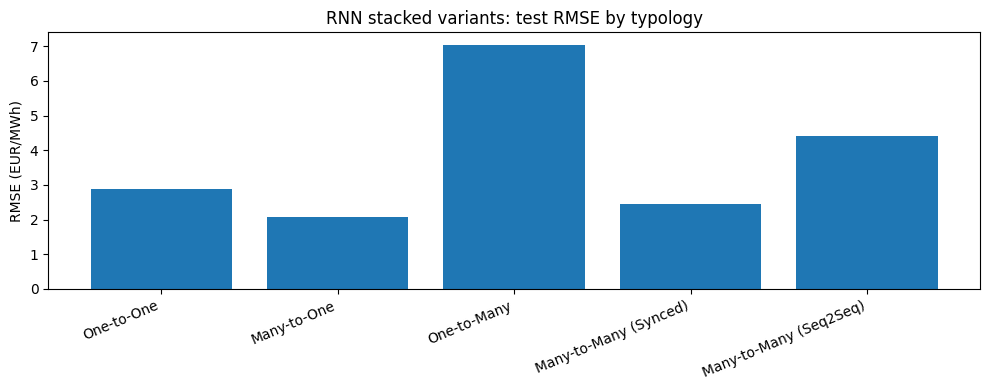

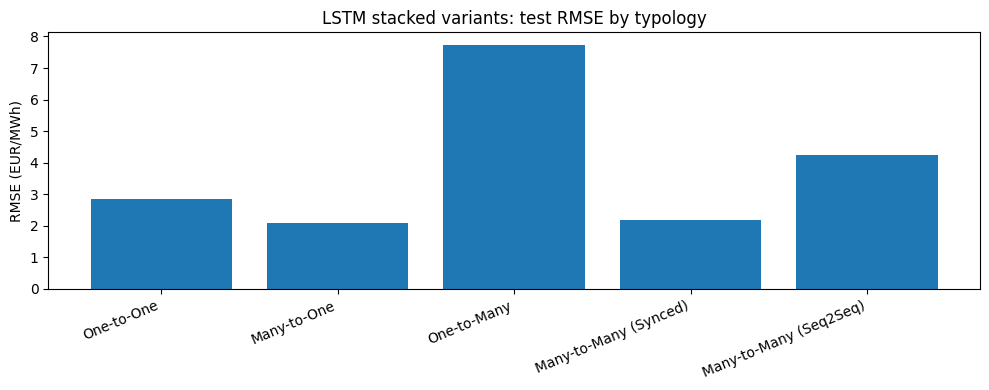

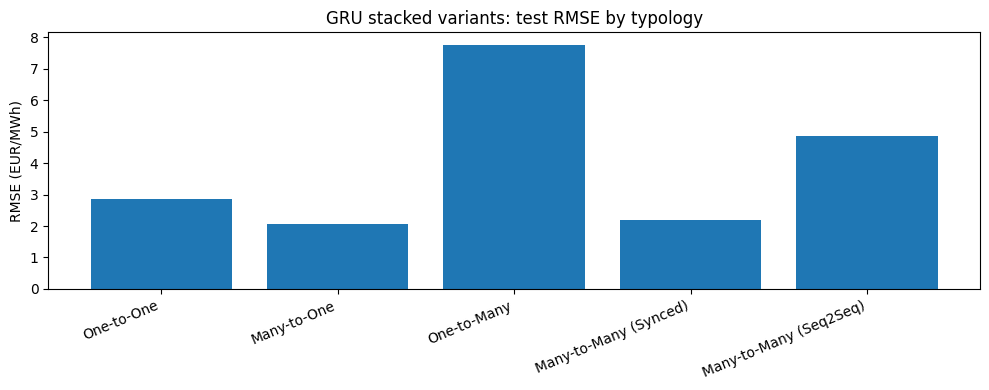

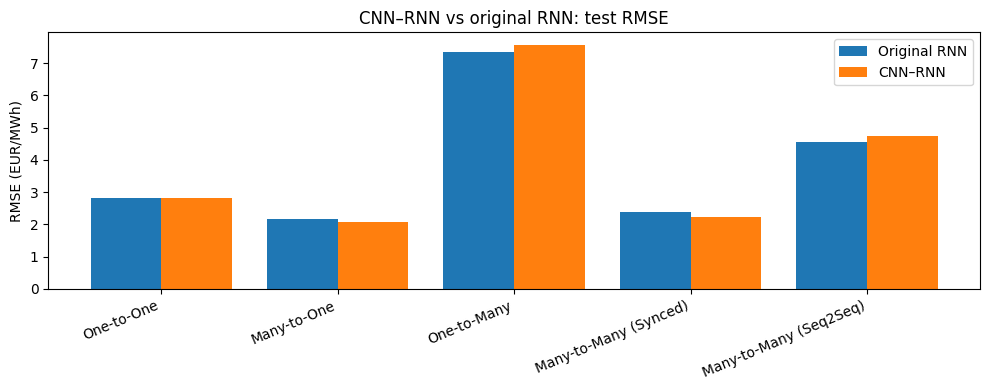

ALL 25/25 EXPERIMENTS COMPLETE.
Report: /content/drive/MyDrive/Bioinformatics/EnergyForecasting_Results/run_c876fda70a14/reports/energy_assignment_measured_report.md
Submission results ZIP: /content/drive/MyDrive/Bioinformatics/EnergyForecasting_Results/run_c876fda70a14/energy_assignment_submission_outputs.zip
Combined metrics CSV: /content/drive/MyDrive/Bioinformatics/EnergyForecasting_Results/run_c876fda70a14/reports/all_energy_model_metrics.csv


In [ ]:
def md_table(frame):
    frame = frame.copy()
    for c in frame.columns:
        if pd.api.types.is_numeric_dtype(frame[c]) and not pd.api.types.is_bool_dtype(frame[c]):
            frame[c] = frame[c].map(lambda v: f'{v:.4f}' if pd.notnull(v) else '')
    cols = list(frame.columns)
    body = ['| ' + ' | '.join(cols) + ' |', '| ' + ' | '.join(['---'] * len(cols)) + ' |']
    for tup in frame.itertuples(index=False, name=None):
        body.append('| ' + ' | '.join(str(v) for v in tup) + ' |')
    return '\n'.join(body)

if len(all_metrics) == 25 and len(paired) == 5:
    stacked = all_metrics[all_metrics.variant == 'stacked'].copy()
    report = [
        '# Energy Forecasting — Experimental Results',
        f'- Experiment run: `{RUN_HASH}`',
        f'- Dataset: `{DATASET_PATH.name}` (SHA256 `{DATA_SHA256}`)',
        f'- Hardware: {GPUS}',
        f'- Epochs per model: {EPOCHS}; batch size: {BATCH_SIZE}; recurrent units: {UNITS}',
        '- Data split: chronological 70% train / 15% validation / 15% test; train-only scaler',
        '- Metrics: MAE, MSE, RMSE, R², computed on held-out test data in original price units (EUR/MWh; MSE squared)',
        '',
        '## Stacked recurrent models: five typologies per family',
    ]
    for family in ('RNN','LSTM','GRU'):
        family_rows = stacked[stacked.family == family].sort_values('RMSE')
        best = family_rows.iloc[0]
        r2top = family_rows.sort_values('R2', ascending=False).iloc[0]
        report += [f'### {family}', md_table(family_rows[['typology','MAE','MSE','RMSE','R2','parameters']]),
                   f'**Lowest-RMSE typology:** `{best.typology}` (RMSE {best.RMSE:.4f}). '
                   f'**Highest-R² typology:** `{r2top.typology}` (R² {r2top.R2:.4f}).', '']
    best_by_topology = stacked.loc[stacked.groupby('typology')['RMSE'].idxmin()]
    report += [
        '## Lowest-RMSE recurrent family for each matched typology',
        md_table(best_by_topology[['typology','family','MAE','MSE','RMSE','R2']]),
        'These within-typology comparisons use the same data and target structure. Different typologies '
        'predict different output horizons/alignments, so their scores should not be used to claim '
        'that one architecture is universally superior.',
        '',
        '## CNN–RNN with 32 filters, kernel size 3, 100 epochs: comparison to original RNN',
        md_table(paired),
    ]
    better = int(paired.CNN_improves_RMSE.sum())
    report.append(f'**Observed result:** CNN–RNN has a lower held-out-test RMSE than the matched original '
                  f'RNN for **{better} of 5 typologies**. This is an association in this run, not proof of a general advantage.')
    for p in paired.itertuples():
        direction = 'decreased (improved)' if p.RMSE_change_pct < 0 else 'increased (worsened)' if p.RMSE_change_pct > 0 else 'did not change'
        report.append(f'- **{TOPOLOGY_LABELS[p.typology]}:** RMSE {direction} by '
                      f'{abs(p.RMSE_change_pct):.2f}% (RNN {p.baseline_RMSE:.4f}; CNN–RNN {p.CNN_RMSE:.4f}).')
    report += [
        '', '## Conclusion and interpretation',
        f'On this test partition, the CNN feature extractor improved RMSE for {better}/5 matched RNN comparisons. '
        'Whether extra convolution helps depends on the input sequence and model, and it can worsen generalization '
        'by adding complexity or overfitting. For one-timestep inputs, the 3-wide kernel is padded and does not '
        'have three real timesteps to extract temporal patterns from. The stacked RNN/LSTM/GRU results indicate '
        'which of the five tested typologies had the lowest measured RMSE within each family (tables above), '
        'but different horizons must be considered when interpreting this ranking.',
        '', '## Limitations',
        '- These are results from one data split and one random seed; repeat seeds to estimate variability.',
        '- Overlapping many-to-many forecast positions are flattened for the overall metrics, '
        'and therefore do not represent independent observations.',
        '- Original One-to-Many and Seq2Seq RNN baselines contain an encoder and decoder; '
        '"one-layer RNN" is shorthand for the source baseline, not literally one layer in those two cases.',
        '- Running 100 epochs as required may overfit; inspect train/validation curves, and avoid selecting on the test set.',
        '- The preprocessing matches the exercise notebooks, including interpolation of missing hourly values.',
        '- Test scores are in original price units; the MSE is in squared units.',
    ]
    report_file = REPORTS_DIR / 'energy_assignment_measured_report.md'
    report_file.write_text('\n\n'.join(report), encoding='utf-8')

    for family in ('RNN','LSTM','GRU'):
        subset = stacked[stacked.family == family].set_index('typology').reindex(TYPOLOGIES)
        plt.figure(figsize=(10,4))
        plt.bar([TOPOLOGY_LABELS[t] for t in TYPOLOGIES], subset.RMSE.values)
        plt.title(f'{family} stacked variants: test RMSE by typology')
        plt.ylabel('RMSE (EUR/MWh)')
        plt.xticks(rotation=23, ha='right')
        plt.tight_layout()
        plt.savefig(REPORTS_DIR / f'{family.lower()}_stacked_rmse.png', dpi=140)
        plt.show()
    plt.figure(figsize=(10,4))
    xp = np.arange(len(paired))
    plt.bar(xp - 0.2, paired.baseline_RMSE, width=0.4, label='Original RNN')
    plt.bar(xp + 0.2, paired.CNN_RMSE, width=0.4, label='CNN–RNN')
    plt.xticks(xp, [TOPOLOGY_LABELS[t] for t in paired.typology], rotation=23, ha='right')
    plt.ylabel('RMSE (EUR/MWh)')
    plt.title('CNN–RNN vs original RNN: test RMSE')
    plt.legend()
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / 'cnn_rnn_vs_baseline_rmse.png', dpi=140)
    plt.show()

    # Small outputs ZIP: avoids including the potentially large .keras and recovery files.
    zip_path = RUN_DIR / 'energy_assignment_submission_outputs.zip'
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
        z.write(MANIFEST_FILE, 'experiment_config.json')
        for p in REPORTS_DIR.glob('*'):
            if p.is_file():
                z.write(p, f'reports/{p.name}')
        for family, typology, variant in EXPERIMENTS:
            root, _, metrics_file, history_file, _ = job_paths(family,typology,variant)
            if metrics_file.exists():
                z.write(metrics_file, f'models/{root.name}/metrics.json')
            if history_file.exists():
                z.write(history_file, f'models/{root.name}/epoch_history.csv')
    print('ALL 25/25 EXPERIMENTS COMPLETE.')
    print('Report:', report_file)
    print('Submission results ZIP:', zip_path)
    print('Combined metrics CSV:', REPORTS_DIR / 'all_energy_model_metrics.csv')
else:
    print(f'Final export intentionally deferred: {len(all_metrics)}/25 models '
          f'and {len(paired)}/5 paired comparisons complete. Rerun all cells to resume.')
    print('Interim metrics, saved models and recovery state:', RUN_DIR)

## 12. Answer checklist and interpretation

1. **Additional recurrent layer:** the 15 stacked models add one same-type **32-neuron** recurrent layer relative to their respective source architecture.
2. **Metrics:** MAE, MSE, RMSE, and R² are exported for each of the five typologies × three stacked model families.
3. **Best typology:** Section 9 shows lowest test RMSE and highest R². The report also compares families **within the same typology**.
4. **CNN–RNN challenge:** one `Conv1D(32, kernel_size=3)` precedes the original RNN. It is trained for **100 epochs**, using `padding='same'` to support one-timestep inputs.
5. **CNN–RNN conclusion:** generated in the report from actual test results, with methodological caveats.
6. **CNN–RNN vs original RNN:** five matched comparisons use all four metrics, including RMSE percentage changes.